In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

df = pd.read_csv("data/fig2_source_data.csv")
df = df.drop(columns=["Unnamed: 0"])
df = df.rename(columns={
    "Fig2a_WetlandDensity": "wetland_density",
    "Fig2b_PercentNRemoval": "pct_n_removal",
    "Fig2c_NSurplus": "n_surplus",
    "Fig2d_EstNRemoval": "est_n_removal",
})
df["region"] = df["HUC8"] // 1_000_000
df.shape

(2098, 6)

In [5]:
from scipy import stats

pairs = [
    ("wetland_density", "n_surplus"),
    ("n_surplus", "est_n_removal"),
    ("wetland_density", "est_n_removal"),
    ("wetland_density", "pct_n_removal"),
]

rows = []
for x, y in pairs:
    r, p_r = stats.pearsonr(df[x], df[y])
    rho, p_s = stats.spearmanr(df[x], df[y])
    lr = stats.linregress(df[x], df[y])
    rows.append([x, y, r, rho, lr.slope, lr.intercept, lr.rvalue**2, lr.pvalue])

results = pd.DataFrame(rows, columns=["x", "y", "pearson_r", "spearman_rho",
                                      "slope", "intercept", "R2", "p"])
results.round(4)

,x,y,pearson_r,spearman_rho,slope,intercept,R2,p
0,wetland_density,n_surplus,-0.0045,0.2575,-0.7440,14.3072,0.0000,0.8384
1,n_surplus,est_n_removal,0.7106,0.8685,0.0870,0.2432,0.5049,0.0000
2,wetland_density,est_n_removal,0.3491,0.6846,7.1393,0.9697,0.1219,0.0000
3,wetland_density,pct_n_removal,0.8167,0.9994,1.2089,0.1115,0.6670,0.0000


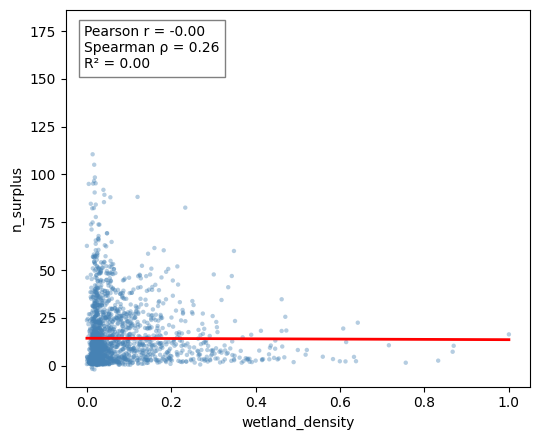

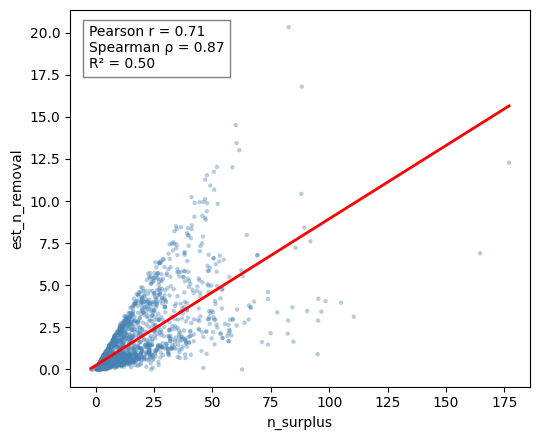

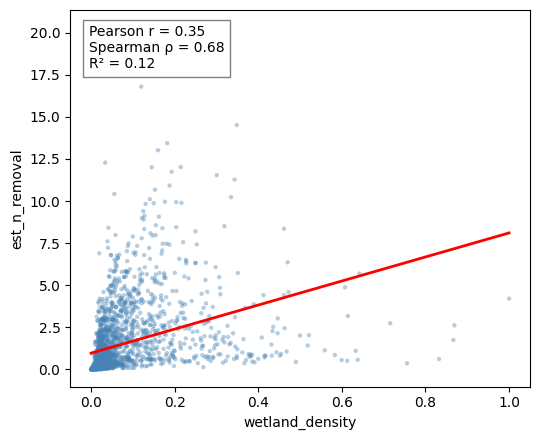

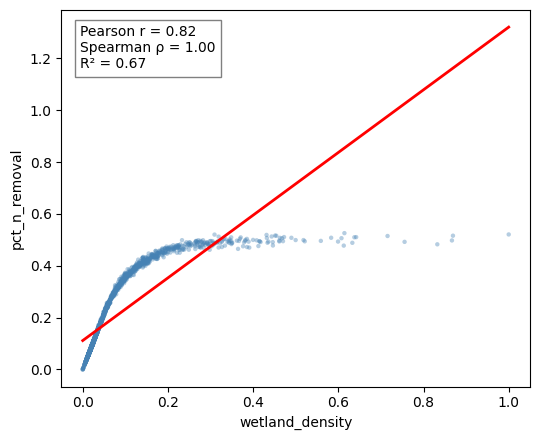

In [9]:
for x, y in pairs:
    lr = stats.linregress(df[x], df[y])
    r, _ = stats.pearsonr(df[x], df[y])
    rho, _ = stats.spearmanr(df[x], df[y])
    xs = np.linspace(df[x].min(), df[x].max(), 100)

    fig, ax = plt.subplots(figsize=(5.5, 4.5))
    ax.scatter(df[x], df[y], s=10, alpha=0.4, color="steelblue", edgecolor="none")
    ax.plot(xs, lr.intercept + lr.slope * xs, color="red", lw=2)
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.text(0.04, 0.96, f"Pearson r = {r:.2f}\nSpearman ρ = {rho:.2f}\nR² = {lr.rvalue**2:.2f}",
            transform=ax.transAxes, va="top",
            bbox=dict(facecolor="white", edgecolor="gray"))
    fig.tight_layout()
    fig.savefig(f"figures/scatter_{x}_vs_{y}.png", dpi=300)
    plt.show()

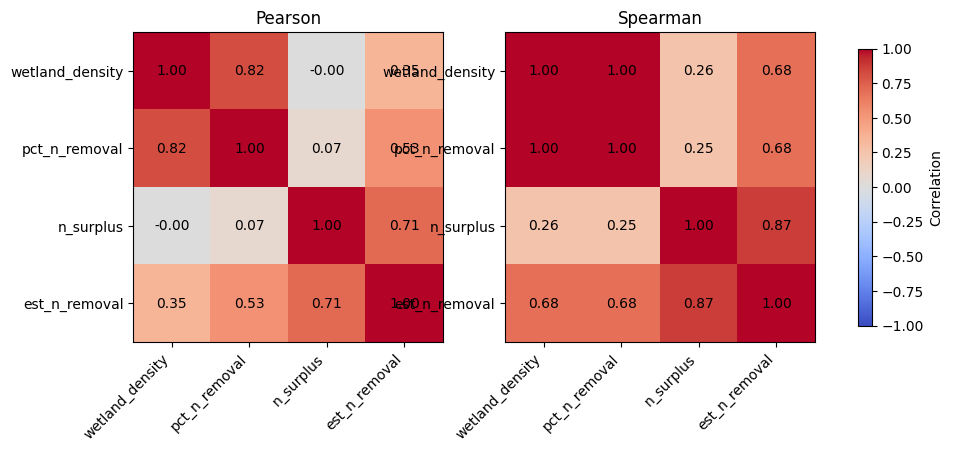

In [11]:
quant = ["wetland_density", "pct_n_removal", "n_surplus", "est_n_removal"]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, method in zip(axes, ["pearson", "spearman"]):
    corr = df[quant].corr(method=method)
    im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(len(quant)))
    ax.set_yticks(range(len(quant)))
    ax.set_xticklabels(quant, rotation=45, ha="right")
    ax.set_yticklabels(quant)
    for i in range(len(quant)):
        for j in range(len(quant)):
            ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center")
    ax.set_title(method.capitalize())
fig.colorbar(im, ax=axes, shrink=0.8, label="Correlation")
fig.savefig("figures/corr_heatmaps.png", dpi=300, bbox_inches="tight")
plt.show()